In [1]:
# ============================================================
# CELL 1 — CLEAR GPU MEMORY
# ============================================================

import gc
import torch

print("=" * 60)
print("GPU MEMORY CLEANUP")
print("=" * 60)

if torch.cuda.is_available():

    print("\nGPU:", torch.cuda.get_device_name(0))

    # Synchronize GPU operations
    torch.cuda.synchronize()

    # Delete unused Python objects
    gc.collect()

    # Clear PyTorch CUDA cache
    torch.cuda.empty_cache()

    # Release unused IPC memory
    torch.cuda.ipc_collect()

    torch.cuda.synchronize()

    allocated = torch.cuda.memory_allocated(0) / 1024**3
    reserved = torch.cuda.memory_reserved(0) / 1024**3
    total = torch.cuda.get_device_properties(0).total_memory / 1024**3

    print(f"\nTotal GPU memory    : {total:.2f} GB")
    print(f"Allocated memory    : {allocated:.2f} GB")
    print(f"Reserved memory     : {reserved:.2f} GB")
    print(f"Free PyTorch memory : {total - reserved:.2f} GB")

else:
    print("\n❌ CUDA is not available.")

GPU MEMORY CLEANUP

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

Total GPU memory    : 6.00 GB
Allocated memory    : 0.00 GB
Reserved memory     : 0.00 GB
Free PyTorch memory : 6.00 GB


In [2]:
# ============================================================
# CELL 2 — TRAINING ENVIRONMENT CHECK
# ============================================================

import torch
import ultralytics

print("=" * 70)
print("TRAINING ENVIRONMENT")
print("=" * 70)

print("PyTorch version :", torch.__version__)
print("Ultralytics    :", ultralytics.__version__)
print("CUDA available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
    print("CUDA version    :", torch.version.cuda)

    total_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3
    )

    print(f"GPU memory      : {total_memory:.2f} GB")

else:
    print("\n❌ CUDA is NOT available.")

TRAINING ENVIRONMENT
PyTorch version : 2.11.0+cu128
Ultralytics    : 8.4.128
CUDA available  : True
GPU             : NVIDIA GeForce RTX 3050 6GB Laptop GPU
CUDA version    : 12.8
GPU memory      : 6.00 GB


In [3]:
# ============================================================
# CELL 3 — RDD4 DATASET CONFIGURATION
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path(r"D:\sih-rdd2022")

RDD4_ROOT = PROJECT_ROOT / "datasets" / "processed" / "rdd4"

DATA_YAML = RDD4_ROOT / "data.yaml"

TRAIN_IMAGES = RDD4_ROOT / "images" / "train"
VAL_IMAGES = RDD4_ROOT / "images" / "val"

TRAIN_LABELS = RDD4_ROOT / "labels" / "train"
VAL_LABELS = RDD4_ROOT / "labels" / "val"

print("=" * 70)
print("RDD4 DATASET CONFIGURATION")
print("=" * 70)

print("\nProject root :", PROJECT_ROOT)
print("RDD4 root    :", RDD4_ROOT)
print("data.yaml    :", DATA_YAML)

print("\nDataset paths exist:")
print("RDD4 root    :", RDD4_ROOT.exists())
print("data.yaml    :", DATA_YAML.exists())
print("Train images :", TRAIN_IMAGES.exists())
print("Train labels :", TRAIN_LABELS.exists())
print("Val images   :", VAL_IMAGES.exists())
print("Val labels   :", VAL_LABELS.exists())

print("\nFile counts:")
print("Train images :", len(list(TRAIN_IMAGES.glob("*"))))
print("Train labels :", len(list(TRAIN_LABELS.glob("*.txt"))))
print("Val images   :", len(list(VAL_IMAGES.glob("*"))))
print("Val labels   :", len(list(VAL_LABELS.glob("*.txt"))))

RDD4 DATASET CONFIGURATION

Project root : D:\sih-rdd2022
RDD4 root    : D:\sih-rdd2022\datasets\processed\rdd4
data.yaml    : D:\sih-rdd2022\datasets\processed\rdd4\data.yaml

Dataset paths exist:
RDD4 root    : True
data.yaml    : True
Train images : True
Train labels : True
Val images   : True
Val labels   : True

File counts:
Train images : 13629
Train labels : 13629
Val images   : 3408
Val labels   : 3408


In [4]:
# ============================================================
# CELL 4 — VERIFY DATA.YAML
# ============================================================

print("=" * 70)
print("RDD4 DATA.YAML")
print("=" * 70)

with open(DATA_YAML, "r", encoding="utf-8") as f:
    yaml_text = f.read()

print(yaml_text)

RDD4 DATA.YAML
path: D:/sih-rdd2022/datasets/processed/rdd4
train: images/train
val: images/val

names:
  0: D00
  1: D10
  2: D20
  3: D40



In [4]:
# ============================================================
# CELL 3 — RDD4 DATASET CONFIGURATION
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path(r"D:\sih-rdd2022")

RDD4_ROOT = PROJECT_ROOT / "datasets" / "processed" / "rdd4"

DATA_YAML = RDD4_ROOT / "data.yaml"

TRAIN_IMAGES = RDD4_ROOT / "images" / "train"
VAL_IMAGES = RDD4_ROOT / "images" / "val"

TRAIN_LABELS = RDD4_ROOT / "labels" / "train"
VAL_LABELS = RDD4_ROOT / "labels" / "val"

# Training output directory
RUNS_DIR = RDD4_ROOT / "runs"

print("=" * 70)
print("RDD4 DATASET CONFIGURATION")
print("=" * 70)

print("DATA_YAML:", DATA_YAML)
print("Exists:", DATA_YAML.exists())

print("\nTrain images:", len(list(TRAIN_IMAGES.glob("*"))))
print("Train labels:", len(list(TRAIN_LABELS.glob("*.txt"))))

print("Val images:", len(list(VAL_IMAGES.glob("*"))))
print("Val labels:", len(list(VAL_LABELS.glob("*.txt"))))

RDD4 DATASET CONFIGURATION
DATA_YAML: D:\sih-rdd2022\datasets\processed\rdd4\data.yaml
Exists: True

Train images: 13629
Train labels: 13629
Val images: 3408
Val labels: 3408


In [5]:
# ============================================================
# CELL 5 — YOLOv8s RDD4 TRAINING
# ============================================================

from ultralytics import YOLO

# ------------------------------------------------------------
# LOAD PRETRAINED MODEL
# ------------------------------------------------------------

model = YOLO("yolov8s.pt")

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

results = model.train(
    # Dataset
    data=str(DATA_YAML),

    # Model / input
    imgsz=640,

    # Training duration
    epochs=120,
    patience=20,

    # Batch / GPU
    batch=8,
    device=0,
    workers=4,

    # Optimizer
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    weight_decay=0.0005,

    # Warmup
    warmup_epochs=3.0,
    warmup_momentum=0.8,
    warmup_bias_lr=0.1,

    # --------------------------------------------------------
    # AUGMENTATION
    # --------------------------------------------------------

    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    degrees=2.0,
    translate=0.1,
    scale=0.5,
    shear=0.0,
    perspective=0.0,

    fliplr=0.5,
    flipud=0.0,

    mosaic=1.0,
    mixup=0.1,

    # Disable unnecessary augmentation
    copy_paste=0.0,

    # Stop mosaic near the end
    close_mosaic=10,

    # --------------------------------------------------------
    # OUTPUT
    # --------------------------------------------------------

    project=str(RUNS_DIR),
    name="yolov8s_rdd4",
    exist_ok=True,

    save=True,
    save_period=10,
    plots=True,

    # --------------------------------------------------------
    # REPRODUCIBILITY
    # --------------------------------------------------------

    seed=42,

    # Deterministic training
    deterministic=True,

    # Validation
    val=True,

    # Verbose output
    verbose=True
)

Ultralytics 8.4.128  Python-3.13.2 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\sih-rdd2022\datasets\processed\rdd4\data.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=120, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_s

In [6]:
from pathlib import Path

dataset = Path(r"D:\sih-rdd2022\datasets\processed\rdd4")

for path in sorted(dataset.rglob("*")):
    if path.is_dir():
        print("[DIR] ", path)

[DIR]  D:\sih-rdd2022\datasets\processed\rdd4\images
[DIR]  D:\sih-rdd2022\datasets\processed\rdd4\images\train
[DIR]  D:\sih-rdd2022\datasets\processed\rdd4\images\val
[DIR]  D:\sih-rdd2022\datasets\processed\rdd4\labels
[DIR]  D:\sih-rdd2022\datasets\processed\rdd4\labels\train
[DIR]  D:\sih-rdd2022\datasets\processed\rdd4\labels\val
[DIR]  D:\sih-rdd2022\datasets\processed\rdd4\runs
[DIR]  D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4
[DIR]  D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights


In [7]:
yaml_path = dataset / "data.yaml"

print(yaml_path.read_text())

path: D:/sih-rdd2022/datasets/processed/rdd4
train: images/train
val: images/val

names:
  0: D00
  1: D10
  2: D20
  3: D40



In [8]:
from ultralytics import YOLO

model = YOLO(
    r"D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt"
)

results = model.val(
    data=r"D:\sih-rdd2022\datasets\processed\rdd4\data.yaml",
    split="val",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    verbose=True
)

Ultralytics 8.4.128  Python-3.13.2 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.20.1 ms, read: 253.2281.0 MB/s, size: 394.6 KB)
val: Scanning D:\sih-rdd2022\datasets\processed\rdd4\labels\val.cache... 3408 images, 605 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3408/3408 1.8Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 426/426 9.5it/s 44.8s0.1ss
                   all       3408       6996      0.562      0.469       0.48      0.217
                   D00       1268       2906      0.536      0.386      0.401      0.186
                   D10        656       1149      0.504      0.386      0.384      0.143
                   D20       1354       1725       0.64      0.643      0.663      0.338
                   D40        666       1216      0.565      0.463      0.473  

In [9]:
print("Overall Results")
print("=" * 40)

print(f"Precision : {results.box.mp:.4f}")
print(f"Recall    : {results.box.mr:.4f}")
print(f"mAP50     : {results.box.map50:.4f}")
print(f"mAP50-95  : {results.box.map:.4f}")

Overall Results
Precision : 0.5616
Recall    : 0.4693
mAP50     : 0.4801
mAP50-95  : 0.2171


In [11]:
from ultralytics import YOLO

model = YOLO(
    r"D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt"
)

results = model.predict(
    source=r"D:\sih-rdd2022\datasets\processed\rdd4\images\val",
    conf=0.25,
    save=True
)


WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/3408 D:\sih-rdd2022\datasets\processed\rdd4\images\val\India_India_000003.jpg: 640x640 (no detections), 13.2ms
image 2/3408 D:\sih-rdd2022\datasets\processed\rdd4\images\val\India_India_000011.jpg: 640x640 (no detections), 12.9ms
image 3/3408 D:\sih-rdd2022\datasets\processed\rdd4\images\val\India_India_000043.jpg: 640x640 1 D20, 5 D40s, 12.9ms
image 4/3408 D:\sih-rdd2022\datasets\processed\rdd4\images\val\India_India_000086.jpg: 640x640 3 D00s, 12.8

In [13]:
from ultralytics import YOLO
from pathlib import Path
import shutil
import random
import os

# ==============================
# PATHS
# ==============================

MODEL_PATH = r"D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt"
VAL_IMAGES = Path(r"D:\sih-rdd2022\datasets\processed\rdd4\images\val")
OUTPUT_DIR = Path(r"D:\sih-rdd2022\failure_analysis")

# ==============================
# CREATE OUTPUT DIRECTORIES
# ==============================

folders = [
    "all_predictions",
    "sample_predictions"
]

for folder in folders:
    (OUTPUT_DIR / folder).mkdir(parents=True, exist_ok=True)

# ==============================
# LOAD MODEL
# ==============================

model = YOLO(MODEL_PATH)

print("Model loaded successfully.")
print(f"Validation images: {len(list(VAL_IMAGES.glob('*')))}")

Model loaded successfully.
Validation images: 3408


In [14]:
results = model.predict(
    source=str(VAL_IMAGES),
    conf=0.25,
    save=True,
    project=str(OUTPUT_DIR),
    name="all_predictions",
    exist_ok=True,
    verbose=False
)

print(f"Processed {len(results)} validation images.")

WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs



error: OpenCV(4.13.0) D:\a\opencv-python\opencv-python\opencv\modules\core\src\alloc.cpp:73: error: (-4:Insufficient memory) Failed to allocate 1228800 bytes in function 'cv::OutOfMemoryError'


In [1]:
from ultralytics import YOLO

MODEL_PATH = r"D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt"

model = YOLO(MODEL_PATH)

print("Model loaded successfully!")
print(MODEL_PATH)

Model loaded successfully!
D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt


In [2]:
from pathlib import Path
import random
import cv2
from IPython.display import display, Image

# Validation image directory
VAL_DIR = Path(r"D:\sih-rdd2022\datasets\processed\rdd4\images\val")

# Output directory
OUTPUT_DIR = Path(r"D:\sih-rdd2022\failure_analysis\sample_predictions")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Get validation images
images = [
    p for p in VAL_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

# Select 30 images automatically
random.seed(42)
sample_images = random.sample(images, min(30, len(images)))

print(f"Total validation images: {len(images)}")
print(f"Testing: {len(sample_images)} images")

Total validation images: 3408
Testing: 30 images


In [3]:
# Run inference one image at a time
for i, img_path in enumerate(sample_images, 1):

    results = model.predict(
        source=str(img_path),
        conf=0.25,
        imgsz=640,
        save=False,
        verbose=False
    )

    result = results[0]

    # Draw predictions
    annotated = result.plot()

    # Save result
    output_path = OUTPUT_DIR / f"{i:02d}_{img_path.name}"
    cv2.imwrite(str(output_path), annotated)

print("✅ Inference completed successfully.")
print(f"Results saved to:\n{OUTPUT_DIR}")

✅ Inference completed successfully.
Results saved to:
D:\sih-rdd2022\failure_analysis\sample_predictions


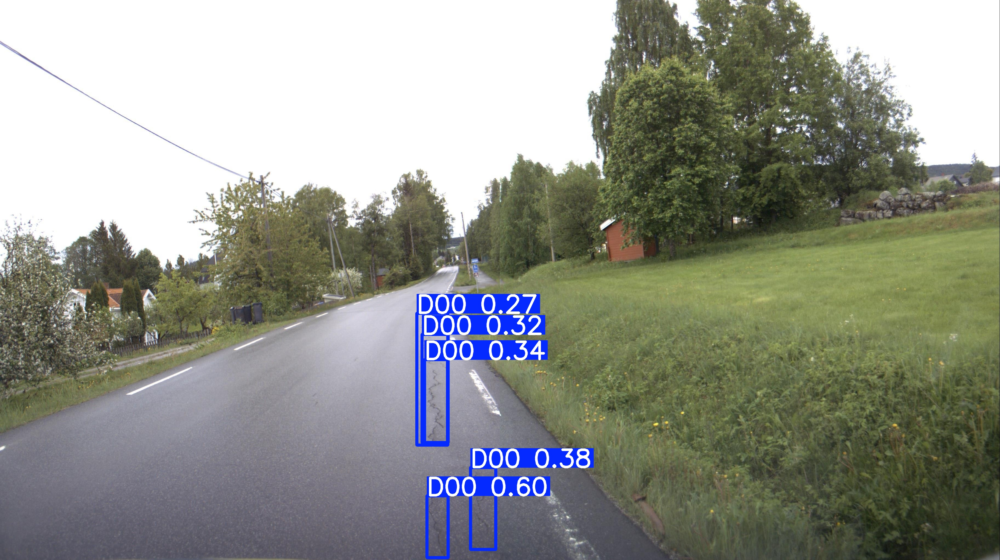

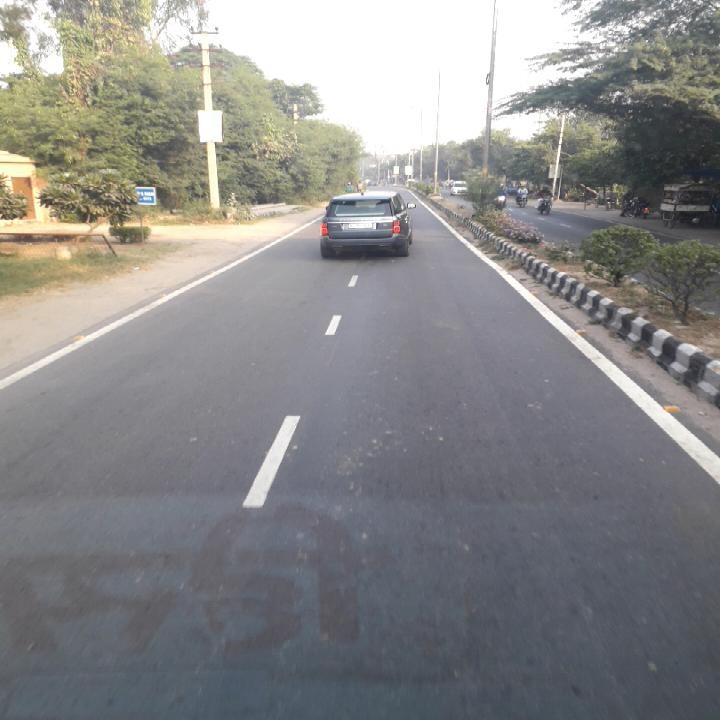

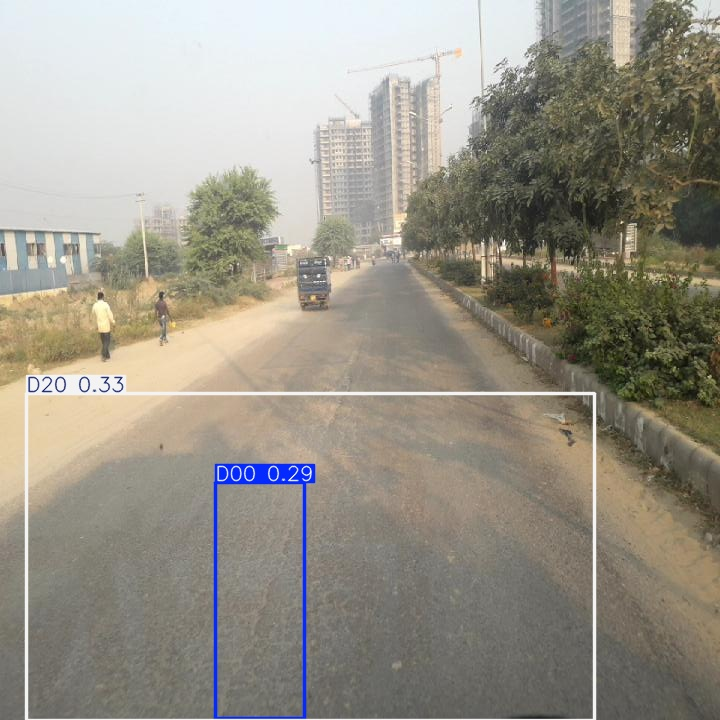

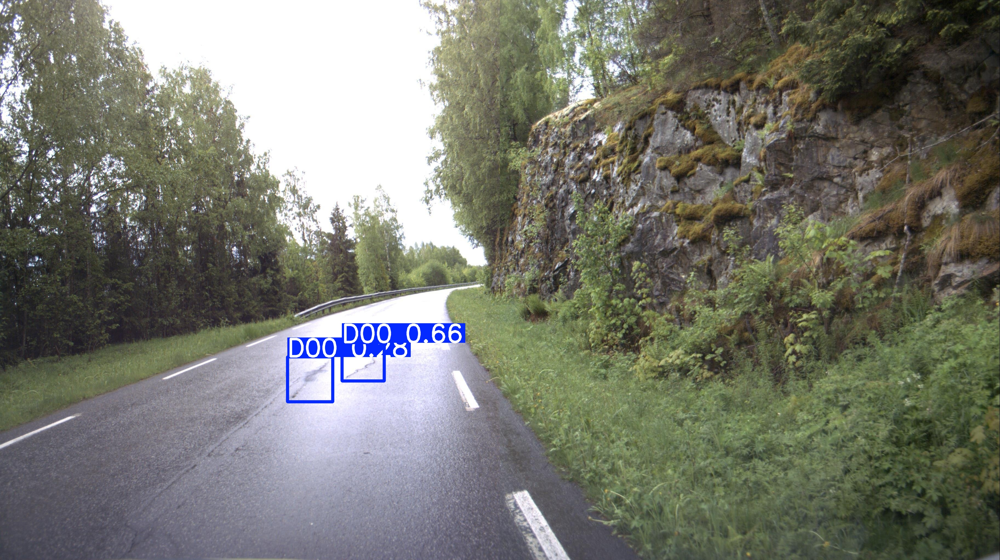

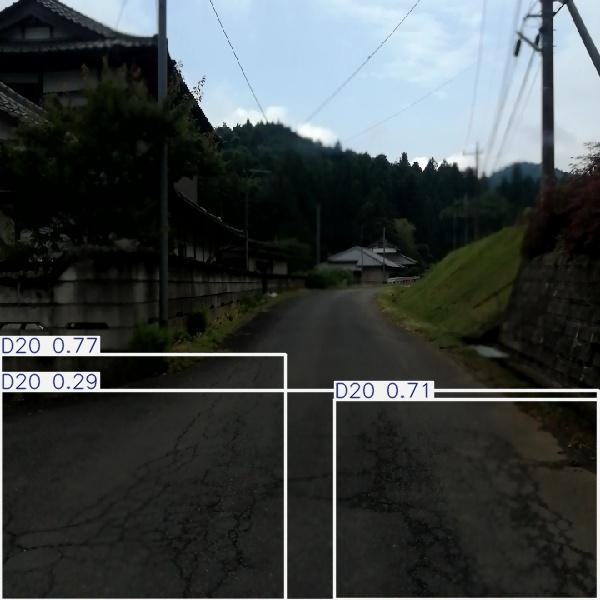

...

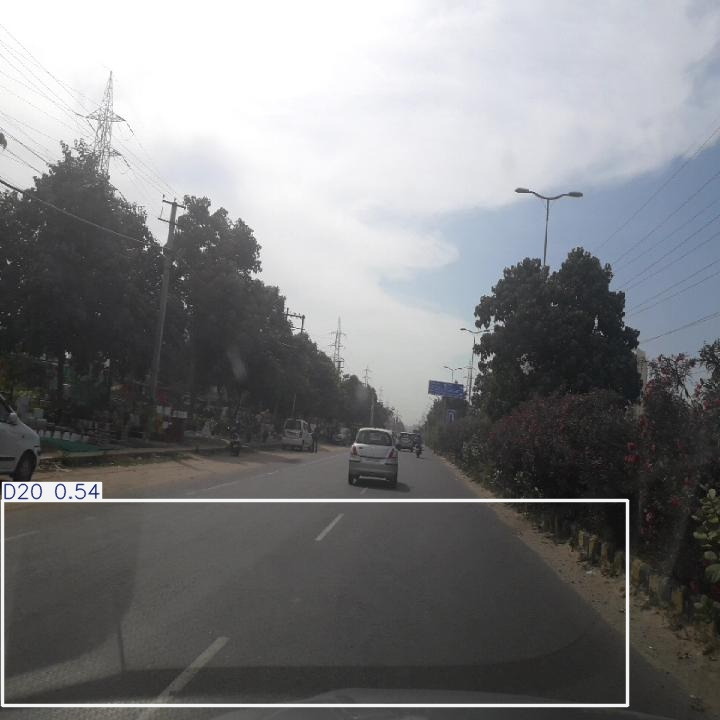

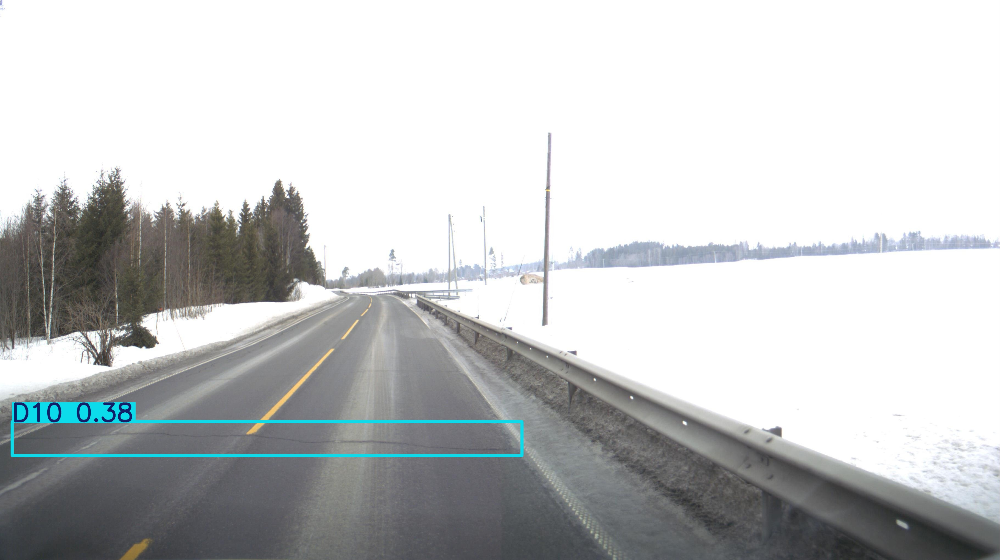

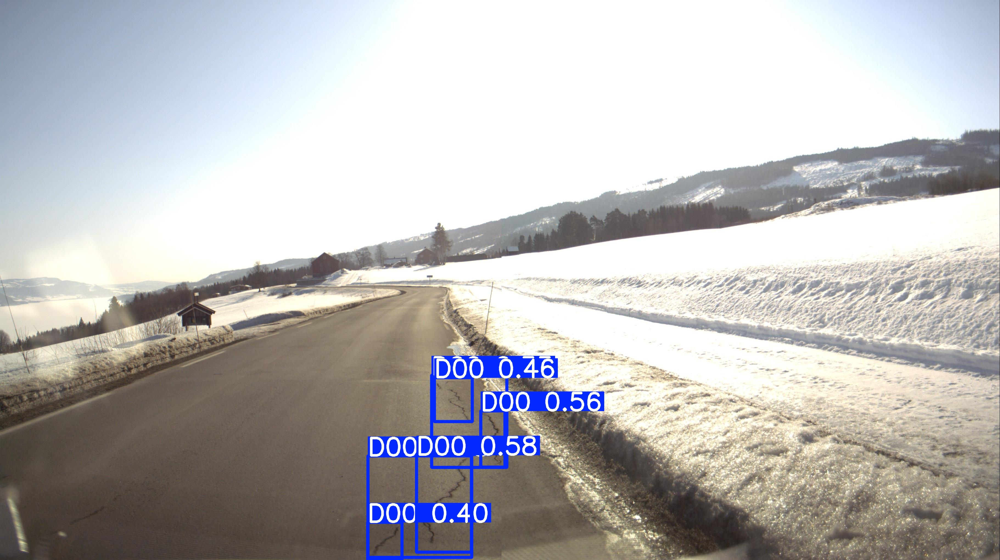

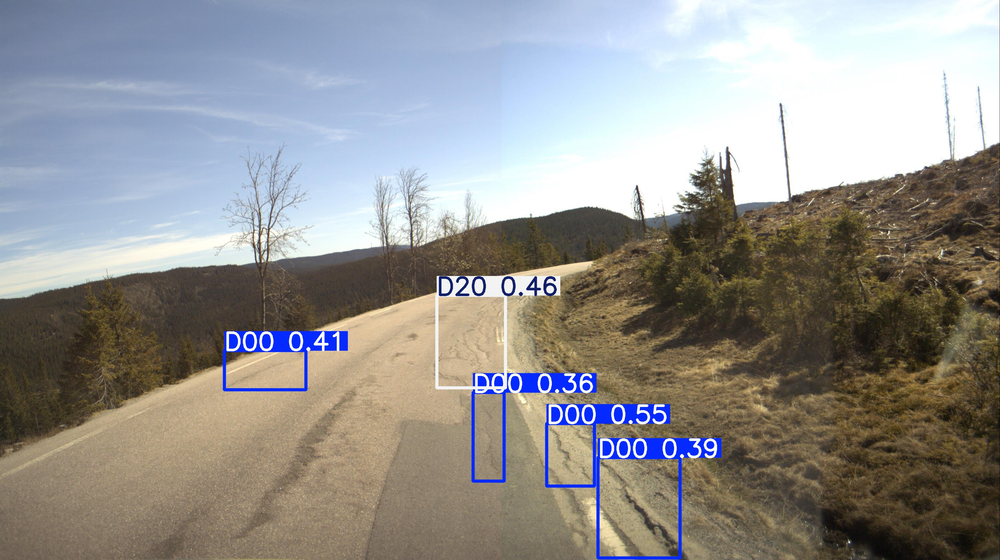

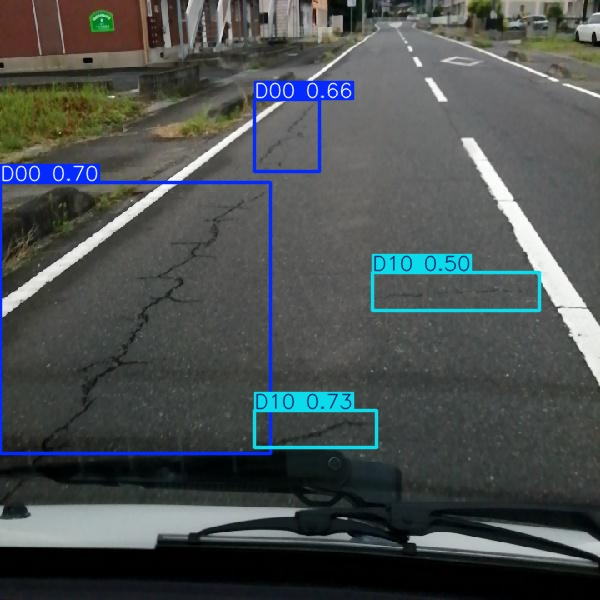

In [4]:
for img_path in sorted(OUTPUT_DIR.iterdir()):

    if img_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        display(Image(filename=str(img_path), width=600))

In [5]:
from pathlib import Path
import numpy as np
import cv2
from collections import defaultdict
from ultralytics import YOLO

# ============================================
# PATHS
# ============================================

MODEL_PATH = r"D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt"

VAL_IMAGES = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\images\val"
)

VAL_LABELS = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\labels\val"
)

OUTPUT_DIR = Path(
    r"D:\sih-rdd2022\failure_analysis"
)

# Maximum examples to save for each category
MAX_EXAMPLES = 20

IOU_THRESHOLD = 0.50
CONF_THRESHOLD = 0.25

# ============================================
# OUTPUT FOLDERS
# ============================================

categories = [
    "missed_detections",
    "false_positives",
    "wrong_class",
    "correct"
]

for category in categories:
    (OUTPUT_DIR / category).mkdir(parents=True, exist_ok=True)

# ============================================
# MODEL
# ============================================

model = YOLO(MODEL_PATH)

class_names = {
    0: "D00",
    1: "D10",
    2: "D20",
    3: "D40"
}

# ============================================
# STATISTICS
# ============================================

stats = {
    "images": 0,
    "ground_truth": 0,
    "predictions": 0,
    "correct": 0,
    "wrong_class": 0,
    "missed": 0,
    "false_positive": 0
}

class_stats = defaultdict(
    lambda: {
        "gt": 0,
        "correct": 0,
        "wrong_class": 0,
        "missed": 0
    }
)

saved_counts = defaultdict(int)


# ============================================
# IoU FUNCTION
# ============================================

def calculate_iou(box1, box2):
    """
    box format:
    [x1, y1, x2, y2]
    """

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection_w = max(0, x2 - x1)
    intersection_h = max(0, y2 - y1)

    intersection = intersection_w * intersection_h

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union


# ============================================
# READ YOLO LABELS
# ============================================

def read_labels(label_path, width, height):

    gt_boxes = []

    if not label_path.exists():
        return gt_boxes

    with open(label_path, "r") as f:

        for line in f:

            values = line.strip().split()

            if len(values) != 5:
                continue

            cls = int(values[0])

            xc = float(values[1]) * width
            yc = float(values[2]) * height
            w = float(values[3]) * width
            h = float(values[4]) * height

            x1 = xc - w / 2
            y1 = yc - h / 2
            x2 = xc + w / 2
            y2 = yc + h / 2

            gt_boxes.append({
                "class": cls,
                "box": [x1, y1, x2, y2]
            })

    return gt_boxes


# ============================================
# PROCESS ALL VALIDATION IMAGES
# ============================================

print("Starting automatic failure analysis...")
print("This processes images one at a time.")
print()

results = model.predict(
    source=str(VAL_IMAGES),
    conf=CONF_THRESHOLD,
    imgsz=640,
    stream=True,
    verbose=False
)

for result in results:

    stats["images"] += 1

    image_path = Path(result.path)

    # Load original image
    image = cv2.imread(str(image_path))

    if image is None:
        continue

    height, width = image.shape[:2]

    # ----------------------------------------
    # Ground truth
    # ----------------------------------------

    label_path = VAL_LABELS / f"{image_path.stem}.txt"

    gt_boxes = read_labels(
        label_path,
        width,
        height
    )

    stats["ground_truth"] += len(gt_boxes)

    # ----------------------------------------
    # Predictions
    # ----------------------------------------

    predictions = []

    if result.boxes is not None:

        boxes = result.boxes.xyxy.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)
        confidences = result.boxes.conf.cpu().numpy()

        for box, cls, conf in zip(
            boxes,
            classes,
            confidences
        ):

            predictions.append({
                "class": int(cls),
                "confidence": float(conf),
                "box": box.tolist()
            })

    stats["predictions"] += len(predictions)

    # ----------------------------------------
    # Match predictions to GT
    # ----------------------------------------

    matched_gt = set()
    matched_pred = set()

    matches = []

    # Find all possible matches
    possible_matches = []

    for pred_idx, pred in enumerate(predictions):

        for gt_idx, gt in enumerate(gt_boxes):

            iou = calculate_iou(
                pred["box"],
                gt["box"]
            )

            if iou >= IOU_THRESHOLD:

                possible_matches.append(
                    (iou, pred_idx, gt_idx)
                )

    # Highest IoU first
    possible_matches.sort(
        reverse=True,
        key=lambda x: x[0]
    )

    # Greedy matching
    for iou, pred_idx, gt_idx in possible_matches:

        if pred_idx in matched_pred:
            continue

        if gt_idx in matched_gt:
            continue

        matched_pred.add(pred_idx)
        matched_gt.add(gt_idx)

        matches.append(
            (pred_idx, gt_idx, iou)
        )

    # ----------------------------------------
    # Analyze matches
    # ----------------------------------------

    for pred_idx, gt_idx, iou in matches:

        pred = predictions[pred_idx]
        gt = gt_boxes[gt_idx]

        gt_class = gt["class"]
        pred_class = pred["class"]

        class_stats[gt_class]["gt"] += 1

        if gt_class == pred_class:

            stats["correct"] += 1
            class_stats[gt_class]["correct"] += 1

            category = "correct"

        else:

            stats["wrong_class"] += 1
            class_stats[gt_class]["wrong_class"] += 1

            category = "wrong_class"

        # Save representative examples
        if saved_counts[category] < MAX_EXAMPLES:

            annotated = image.copy()

            # GT = green
            gx1, gy1, gx2, gy2 = map(
                int,
                gt["box"]
            )

            cv2.rectangle(
                annotated,
                (gx1, gy1),
                (gx2, gy2),
                (0, 255, 0),
                2
            )

            # Prediction = red
            px1, py1, px2, py2 = map(
                int,
                pred["box"]
            )

            cv2.rectangle(
                annotated,
                (px1, py1),
                (px2, py2),
                (0, 0, 255),
                2
            )

            label = (
                f"GT: {class_names[gt_class]} | "
                f"Pred: {class_names[pred_class]} | "
                f"Conf: {pred['confidence']:.2f} | "
                f"IoU: {iou:.2f}"
            )

            cv2.putText(
                annotated,
                label,
                (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 255, 255),
                2
            )

            output_path = (
                OUTPUT_DIR
                / category
                / f"{saved_counts[category]+1:02d}_{image_path.name}"
            )

            cv2.imwrite(
                str(output_path),
                annotated
            )

            saved_counts[category] += 1

    # ----------------------------------------
    # Missed GT detections
    # ----------------------------------------

    for gt_idx, gt in enumerate(gt_boxes):

        if gt_idx not in matched_gt:

            stats["missed"] += 1

            gt_class = gt["class"]

            class_stats[gt_class]["gt"] += 1
            class_stats[gt_class]["missed"] += 1

            category = "missed_detections"

            if saved_counts[category] < MAX_EXAMPLES:

                annotated = image.copy()

                x1, y1, x2, y2 = map(
                    int,
                    gt["box"]
                )

                cv2.rectangle(
                    annotated,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 255),
                    3
                )

                label = (
                    f"MISSED: "
                    f"{class_names[gt_class]}"
                )

                cv2.putText(
                    annotated,
                    label,
                    (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8,
                    (0, 255, 255),
                    2
                )

                output_path = (
                    OUTPUT_DIR
                    / category
                    / f"{saved_counts[category]+1:02d}_{image_path.name}"
                )

                cv2.imwrite(
                    str(output_path),
                    annotated
                )

                saved_counts[category] += 1

    # ----------------------------------------
    # False positives
    # ----------------------------------------

    for pred_idx, pred in enumerate(predictions):

        if pred_idx not in matched_pred:

            stats["false_positive"] += 1

            category = "false_positives"

            if saved_counts[category] < MAX_EXAMPLES:

                annotated = image.copy()

                x1, y1, x2, y2 = map(
                    int,
                    pred["box"]
                )

                cv2.rectangle(
                    annotated,
                    (x1, y1),
                    (x2, y2),
                    (255, 0, 255),
                    3
                )

                label = (
                    f"FALSE POSITIVE: "
                    f"{class_names[pred['class']]} "
                    f"{pred['confidence']:.2f}"
                )

                cv2.putText(
                    annotated,
                    label,
                    (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (255, 0, 255),
                    2
                )

                output_path = (
                    OUTPUT_DIR
                    / category
                    / f"{saved_counts[category]+1:02d}_{image_path.name}"
                )

                cv2.imwrite(
                    str(output_path),
                    annotated
                )

                saved_counts[category] += 1


    # Progress
    if stats["images"] % 100 == 0:
        print(
            f"Processed {stats['images']}/3408 images..."
        )


print()
print("=" * 50)
print("FAILURE ANALYSIS COMPLETE")
print("=" * 50)

print(f"Images processed    : {stats['images']}")
print(f"Ground truth boxes  : {stats['ground_truth']}")
print(f"Predicted boxes     : {stats['predictions']}")
print(f"Correct detections  : {stats['correct']}")
print(f"Wrong classifications: {stats['wrong_class']}")
print(f"Missed detections   : {stats['missed']}")
print(f"False positives     : {stats['false_positive']}")

print()
print("Saved examples:")
for category in categories:
    print(
        f"{category:20s}: "
        f"{saved_counts[category]}"
    )

print()
print(f"Results directory:")
print(OUTPUT_DIR)

Starting automatic failure analysis...
This processes images one at a time.

Processed 100/3408 images...
Processed 200/3408 images...
Processed 300/3408 images...
Processed 400/3408 images...
Processed 500/3408 images...
Processed 600/3408 images...
Processed 700/3408 images...
Processed 800/3408 images...
Processed 900/3408 images...
Processed 1000/3408 images...
Processed 1100/3408 images...
Processed 1200/3408 images...
Processed 1300/3408 images...
Processed 1400/3408 images...
Processed 1500/3408 images...
Processed 1600/3408 images...
Processed 1700/3408 images...
Processed 1800/3408 images...
Processed 1900/3408 images...
Processed 2000/3408 images...
Processed 2100/3408 images...
Processed 2200/3408 images...
Processed 2300/3408 images...
Processed 2400/3408 images...
Processed 2500/3408 images...
Processed 2600/3408 images...
Processed 2700/3408 images...
Processed 2800/3408 images...
Processed 2900/3408 images...
Processed 3000/3408 images...
Processed 3100/3408 images...
Pr

In [6]:
from pathlib import Path

FAILURE_DIR = Path(r"D:\sih-rdd2022\failure_analysis")

print("Failure analysis folders:")
for folder in FAILURE_DIR.iterdir():
    if folder.is_dir():
        files = list(folder.glob("*"))
        print(f"{folder.name:20s} : {len(files)} files")

Failure analysis folders:
all_predictions      : 1791 files
correct              : 20 files
false_positives      : 20 files
missed_detections    : 20 files
sample_predictions   : 30 files
wrong_class          : 20 files


In [7]:
from PIL import Image, ImageDraw
from pathlib import Path
import math

def create_contact_sheet(folder_name, output_name, thumb_size=(320, 240), cols=4):
    folder = FAILURE_DIR / folder_name
    images = []

    files = sorted([
        f for f in folder.iterdir()
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    for f in files:
        try:
            img = Image.open(f).convert("RGB")
            img.thumbnail(thumb_size)
            
            canvas = Image.new("RGB", thumb_size, "white")
            x = (thumb_size[0] - img.width) // 2
            y = (thumb_size[1] - img.height) // 2
            canvas.paste(img, (x, y))

            draw = ImageDraw.Draw(canvas)
            draw.text((5, 5), f.name[:35], fill="black")

            images.append(canvas)
        except:
            pass

    if not images:
        print(f"No images found in {folder}")
        return

    rows = math.ceil(len(images) / cols)

    sheet = Image.new(
        "RGB",
        (cols * thumb_size[0], rows * thumb_size[1]),
        "white"
    )

    for i, img in enumerate(images):
        x = (i % cols) * thumb_size[0]
        y = (i // cols) * thumb_size[1]
        sheet.paste(img, (x, y))

    output = FAILURE_DIR / output_name
    sheet.save(output)

    print(f"Saved: {output}")


create_contact_sheet(
    "missed_detections",
    "missed_contact_sheet.jpg"
)

create_contact_sheet(
    "false_positives",
    "false_positive_contact_sheet.jpg"
)

create_contact_sheet(
    "wrong_class",
    "wrong_class_contact_sheet.jpg"
)

create_contact_sheet(
    "correct",
    "correct_contact_sheet.jpg"
)

Saved: D:\sih-rdd2022\failure_analysis\missed_contact_sheet.jpg
Saved: D:\sih-rdd2022\failure_analysis\false_positive_contact_sheet.jpg
Saved: D:\sih-rdd2022\failure_analysis\wrong_class_contact_sheet.jpg
Saved: D:\sih-rdd2022\failure_analysis\correct_contact_sheet.jpg


In [8]:
from ultralytics import YOLO
import pandas as pd
import gc
import torch

# ==============================
# PATHS
# ==============================
MODEL_PATH = r"D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt"
DATA_YAML = r"D:\sih-rdd2022\datasets\processed\rdd4\data.yaml"

# Load model
model = YOLO(MODEL_PATH)

print("Model loaded successfully!")
print(MODEL_PATH)

# ==============================
# CONFIDENCE THRESHOLDS
# ==============================
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60, 0.70]

results_table = []

print("\nStarting confidence threshold experiment...")
print("=" * 70)

for conf in thresholds:

    print(f"\nTesting confidence = {conf:.2f}")

    results = model.val(
        data=DATA_YAML,
        split="val",
        imgsz=640,
        batch=8,
        conf=conf,
        iou=0.7,
        device=0,
        workers=2,
        plots=False,
        save_json=False,
        verbose=False
    )

    precision = float(results.box.mp)
    recall = float(results.box.mr)
    map50 = float(results.box.map50)
    map5095 = float(results.box.map)

    results_table.append({
        "Confidence": conf,
        "Precision": precision,
        "Recall": recall,
        "mAP50": map50,
        "mAP50-95": map5095
    })

    print(
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"mAP50: {map50:.4f} | "
        f"mAP50-95: {map5095:.4f}"
    )

    # Free memory
    del results
    gc.collect()
    torch.cuda.empty_cache()

# ==============================
# DISPLAY RESULTS
# ==============================
df_threshold = pd.DataFrame(results_table)

print("\n" + "=" * 70)
print("CONFIDENCE THRESHOLD RESULTS")
print("=" * 70)

display(
    df_threshold.style.format({
        "Confidence": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)

# Save results
OUTPUT_CSV = r"D:\sih-rdd2022\failure_analysis\confidence_threshold_results.csv"
df_threshold.to_csv(OUTPUT_CSV, index=False)

print(f"\nResults saved to:")
print(OUTPUT_CSV)

Model loaded successfully!
D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt

Starting confidence threshold experiment...

Testing confidence = 0.10
Ultralytics 8.4.128  Python-3.13.2 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 1086.3772.0 MB/s, size: 252.2 KB)
val: Scanning D:\sih-rdd2022\datasets\processed\rdd4\labels\val.cache... 3408 images, 605 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3408/3408 1.0Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 426/426 9.9it/s 43.0s<0.1ss
                   all       3408       6996      0.562      0.469      0.438      0.199
Speed: 0.7ms preprocess, 8.6ms inference, 0.0ms loss, 0.6ms postprocess per image
Precision: 0.5616 | Recall: 0.4693 | mAP50: 0.4378 | mAP50-95: 0.1985

Testing confidence 

,Confidence,Precision,Recall,mAP50,mAP50-95
0,0.10,0.5616,0.4693,0.4378,0.1985
1,0.15,0.5616,0.4693,0.4152,0.1900
2,0.20,0.5473,0.4784,0.3909,0.1808
3,0.25,0.5830,0.4526,0.3662,0.1710
4,0.30,0.6435,0.4091,0.3387,0.1611
5,0.35,0.6956,0.3683,0.3122,0.1510
6,0.40,0.7312,0.3220,0.2783,0.1379
7,0.50,0.8025,0.2365,0.2146,0.1117
8,0.60,0.8646,0.1582,0.1445,0.0818
9,0.70,0.9297,0.0848,0.0840,0.0488



Results saved to:
D:\sih-rdd2022\failure_analysis\confidence_threshold_results.csv


In [9]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import gc
import torch

# ==========================================
# PATHS
# ==========================================
MODEL_PATH = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt"
)

INPUT_DIR = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\images\val"
)

OUTPUT_DIR = Path(
    r"D:\sih-rdd2022\prototype_inference"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# SETTINGS
# ==========================================
CONF_THRESHOLD = 0.20
IMG_SIZE = 640

# ==========================================
# LOAD MODEL
# ==========================================
model = YOLO(str(MODEL_PATH))

print("Model loaded successfully!")
print(MODEL_PATH)

# ==========================================
# FIND IMAGES
# ==========================================
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = sorted([
    p for p in INPUT_DIR.iterdir()
    if p.suffix.lower() in image_extensions
])

print(f"\nImages found: {len(image_paths)}")

# ==========================================
# OUTPUT DIRECTORIES
# ==========================================
ANNOTATED_DIR = OUTPUT_DIR / "annotated"
ANNOTATED_DIR.mkdir(exist_ok=True)

# ==========================================
# INFERENCE
# ==========================================
prediction_rows = []

class_counts = {
    "D00": 0,
    "D10": 0,
    "D20": 0,
    "D40": 0
}

total_images_with_detection = 0
total_images_without_detection = 0

print("\nStarting prototype inference...")
print("=" * 60)

for i, image_path in enumerate(image_paths, start=1):

    # Process ONE image at a time
    results = model.predict(
        source=str(image_path),
        conf=CONF_THRESHOLD,
        imgsz=IMG_SIZE,
        device=0,
        save=True,
        project=str(OUTPUT_DIR),
        name="annotated",
        exist_ok=True,
        verbose=False
    )

    result = results[0]

    boxes = result.boxes

    if boxes is not None and len(boxes) > 0:

        total_images_with_detection += 1

        for box in boxes:

            cls_id = int(box.cls[0])
            confidence = float(box.conf[0])

            xyxy = box.xyxy[0].cpu().numpy()

            class_name = model.names[cls_id]

            if class_name in class_counts:
                class_counts[class_name] += 1

            prediction_rows.append({
                "image": image_path.name,
                "class_id": cls_id,
                "class": class_name,
                "confidence": confidence,
                "x1": float(xyxy[0]),
                "y1": float(xyxy[1]),
                "x2": float(xyxy[2]),
                "y2": float(xyxy[3])
            })

    else:
        total_images_without_detection += 1

    # Free memory
    del results
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if i % 100 == 0 or i == len(image_paths):
        print(f"Processed {i}/{len(image_paths)} images")

# ==========================================
# SAVE CSV
# ==========================================
predictions_df = pd.DataFrame(prediction_rows)

CSV_PATH = OUTPUT_DIR / "predictions.csv"

predictions_df.to_csv(CSV_PATH, index=False)

# ==========================================
# SUMMARY
# ==========================================
print("\n")
print("=" * 60)
print("PROTOTYPE INFERENCE COMPLETE")
print("=" * 60)

print(f"Images processed          : {len(image_paths)}")
print(f"Images with detections    : {total_images_with_detection}")
print(f"Images without detections : {total_images_without_detection}")
print(f"Total detections          : {len(prediction_rows)}")

print("\nClass-wise detections:")
for cls, count in class_counts.items():
    print(f"{cls:5s}: {count}")

print("\nPrediction CSV:")
print(CSV_PATH)

print("\nAnnotated images:")
print(ANNOTATED_DIR)

Model loaded successfully!
D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt

Images found: 3408

Starting prototype inference...
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype_inference\annotated
Results saved to D:\sih-rdd2022\prototype

In [10]:
from ultralytics import YOLO
from pathlib import Path
import numpy as np


# ============================================================
# MODEL CONFIGURATION
# ============================================================

MODEL_PATH = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt"
)

CONF_THRESHOLD = 0.20
IMAGE_SIZE = 640


# ============================================================
# LOAD MODEL ONCE
# ============================================================

model = YOLO(str(MODEL_PATH))


# ============================================================
# DAMAGE DETECTION FUNCTION
# ============================================================

def detect_damage(image):
    """
    Run road-damage detection on an image.

    Parameters
    ----------
    image:
        Image path, NumPy array, or image supported by Ultralytics.

    Returns
    -------
    dict:
        Structured detection result.
    """

    results = model.predict(
        source=image,
        conf=CONF_THRESHOLD,
        imgsz=IMAGE_SIZE,
        device=0,
        verbose=False
    )

    result = results[0]

    detections = []

    if result.boxes is not None:

        for box in result.boxes:

            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            bbox = box.xyxy[0].cpu().numpy()

            x1, y1, x2, y2 = bbox

            detections.append({
                "class_id": class_id,
                "class": model.names[class_id],
                "confidence": round(confidence, 4),
                "bbox": [
                    round(float(x1), 2),
                    round(float(y1), 2),
                    round(float(x2), 2),
                    round(float(y2), 2)
                ]
            })

    return {
        "detections": detections,
        "count": len(detections)
    }


# ============================================================
# SIMPLE TEST
# ============================================================

if __name__ == "__main__":

    test_image = r"D:\sih-rdd2022\datasets\processed\rdd4\images\val"

    # Use one actual image for testing.
    test_images = list(Path(test_image).glob("*.jpg"))

    if not test_images:
        print("No test images found.")
    else:

        image = str(test_images[0])

        print("Testing:", image)

        output = detect_damage(image)

        print("\nDetection result:")
        print(output)

Testing: D:\sih-rdd2022\datasets\processed\rdd4\images\val\India_India_000003.jpg

Detection result:
{'detections': [], 'count': 0}


In [11]:
from pathlib import Path

image = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\images\val\India_India_000003.jpg"
)

label = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\labels\val\India_India_000003.txt"
)

print("Image exists :", image.exists())
print("Label exists :", label.exists())

if label.exists():
    print("\nGround-truth label:")
    print(label.read_text())

Image exists : True
Label exists : True

Ground-truth label:



In [12]:
from pathlib import Path

LABEL_DIR = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\labels\val"
)

IMAGE_DIR = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\images\val"
)

# Find first label file containing an annotation
for label_file in LABEL_DIR.glob("*.txt"):

    content = label_file.read_text().strip()

    if content:
        image_file = IMAGE_DIR / f"{label_file.stem}.jpg"

        if image_file.exists():
            print("Found damage image:")
            print(image_file)

            print("\nGround-truth:")
            print(content)

            break

Found damage image:
D:\sih-rdd2022\datasets\processed\rdd4\images\val\India_India_000011.jpg

Ground-truth:
0 0.528472 0.722917 0.034722 0.162500
